# 04. Гарантия: как честно мерить и где «утекают» дефекты

**Вопросы.** (1) Какова реальная частота гарантийных случаев по группам продукции и как её корректно считать? (2) Почему у тяжёлой техники ЦГА и ЦСТ гарантийных обращений по тормозам и ходовой больше, чем ожидалось, и есть ли связь с тем, как изделие испытывали на заводе?

Гарантийные заявки приходят с дилерского портала (отдельная система, грязный JSON - очищен в dbt-staging) и сопоставлены с изделиями по VIN.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.duration.survfunc import SurvfuncRight
from helpers import q, save, pct, label_ends, BLUE, ORANGE, AQUA, GRAY, GRAY_LIGHT, INK_2

units = q("""
select u.unit_id, dm.product_group, dm.category_name, u.workshop_id, u.shipped_date,
       date_trunc('quarter', u.shipped_date)::date as ship_q, u.days_in_service,
       u.warranty_claims_cnt > 0 as claimed, u.days_to_first_claim, u.warranty_cost_rub,
       u.dyn_lab_id, u.dyn_on_retired_stand, u.paint_brigade_id
from marts.fct_units u join marts.dim_model dm using (model_id)
where u.shipped_date is not null
""")
units["duration"] = np.where(units["claimed"], units["days_to_first_claim"], units["days_in_service"]).astype(float)
units["duration"] = units["duration"].clip(lower=0.5)
print(f"Отгружено изделий: {len(units):,}; с гарантийным случаем: {units['claimed'].sum()}".replace(",", " "))

Отгружено изделий: 21 966; с гарантийным случаем: 271


## 1. Ловушка цензурирования
«Доля машин с гарантийным случаем» по кварталу отгрузки выглядит так, будто качество резко улучшилось. Но машины, отгруженные недавно, просто ещё не успели «сломаться»: наблюдение обрезано датой выгрузки (правое цензурирование).

In [2]:
naive = units.groupby("ship_q").agg(units=("unit_id", "size"), claimed=("claimed", "mean"),
                                    median_days=("days_in_service", "median"))

def km_at(df, t):
    sf = SurvfuncRight(df["duration"], df["claimed"].astype(int))
    idx = np.searchsorted(sf.surv_times, t, side="right") - 1
    return 1 - (sf.surv_prob[idx] if idx >= 0 else 1.0)

naive["km_180d"] = [km_at(g, 180) if g["days_in_service"].max() >= 180 else np.nan
                    for _, g in units.groupby("ship_q")]
naive.round(4)

,units,claimed,median_days,km_180d
ship_q,,,,
2024-10-01,2309,0.0173,680.0,0.0065
2025-01-01,2651,0.0177,585.0,0.0060
2025-04-01,2995,0.0180,507.0,0.0090
2025-07-01,2587,0.0197,411.0,0.0101
2025-10-01,2735,0.0113,319.0,0.0055
2026-01-01,2682,0.0093,220.0,0.0067
2026-04-01,3187,0.0066,140.0,0.0075
2026-07-01,2820,0.0007,47.0,NaN


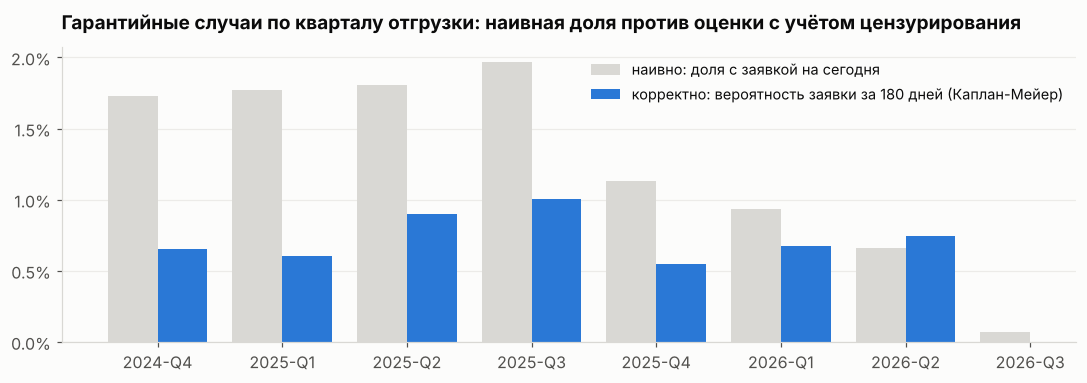

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(naive))
labels = [f"{d.year}-Q{(d.month - 1) // 3 + 1}" for d in naive.index]
ax.bar(x - 0.2, naive["claimed"], width=0.4, color=GRAY_LIGHT, label="наивно: доля с заявкой на сегодня")
ax.bar(x + 0.2, naive["km_180d"], width=0.4, color=BLUE, label="корректно: вероятность заявки за 180 дней (Каплан-Мейер)")
ax.set_xticks(x, labels)
pct(ax, 1)
from matplotlib.ticker import MultipleLocator
ax.yaxis.set_major_locator(MultipleLocator(0.005))
ax.legend(loc="upper right")
ax.set_title("Гарантийные случаи по кварталу отгрузки: наивная доля против оценки с учётом цензурирования")
save(fig, "04_censoring")

Наивная доля «падает» к последним кварталам, хотя вероятность случая за фиксированные 180 дней от квартала к кварталу стабильна. Если показать руководству наивную метрику, оно решит, что качество выросло вдвое. Поэтому на дашборде гарантия показывается когортами с фиксированным горизонтом (витрина `mart_warranty_cohorts`), а в анализе - кривыми Каплана-Мейера.

## 2. Кривые гарантийных случаев по группам продукции

,Тяжёлая техника,Легковые,Мото и прочее
90 дн.,0.57%,0.32%,0.27%
180 дн.,1.13%,0.66%,0.59%
365 дн.,1.83%,1.27%,1.00%
540 дн.,2.50%,1.69%,1.68%


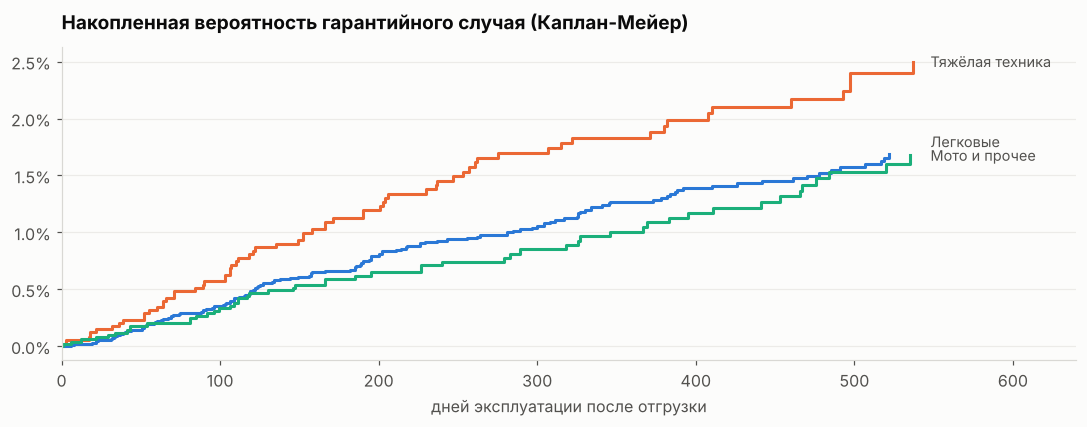

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ends = {}
for grp, color in [("Тяжёлая техника", ORANGE), ("Легковые", BLUE), ("Мото и прочее", AQUA)]:
    d = units[units["product_group"] == grp]
    sf = SurvfuncRight(d["duration"], d["claimed"].astype(int))
    t = np.r_[0, sf.surv_times]
    p = 1 - np.r_[1, sf.surv_prob]
    mask = t <= 540
    ax.step(t[mask], p[mask], where="post", color=color, lw=2)
    ends[grp] = (p[mask][-1], INK_2)
label_ends(ax, 548, ends, min_gap=0.0012)
ax.set_xlim(0, 640)
pct(ax, 1)
ax.set_xlabel("дней эксплуатации после отгрузки")
ax.set_title("Накопленная вероятность гарантийного случая (Каплан-Мейер)")
save(fig, "04_km_groups")

km_tab = pd.DataFrame({grp: [km_at(units[units.product_group == grp], t) for t in (90, 180, 365, 540)]
                       for grp in ["Тяжёлая техника", "Легковые", "Мото и прочее"]},
                      index=["90 дн.", "180 дн.", "365 дн.", "540 дн."])
km_tab.style.format("{:.2%}")

У тяжёлой техники вероятность гарантийного случая за год примерно в 1.5 раза выше, чем у легковых и мото (1.8% против 1.0-1.3%). Отчасти это ожидаемо (сложнее изделие, тяжелее эксплуатация). Проверим, нет ли у этой разницы заводской причины.

## 3. Где «утекают» дефекты тормозов и ходовой
Дефекты сборки тормозной системы, затяжки соединений, течи и регулировок должен ловить **динамический стенд** (испытание DYN). Тяжёлую технику ЦГА и ЦСТ испытывают на стендах двух лабораторий: ИЛ-2 и ИЛ-3. В ИЛ-2 до 02.03.2026 работал тормозной стенд 1998 года, затем его заменили.

**Метрика «утечки».** Дефект DYN-типа, *пропущенный* динамическим стендом и обнаруженный позже - на ходовых испытаниях (обкатке) или у дилера по гарантии. Считаем на 1000 изделий.

In [5]:
leak = q("""
with heavy as (
    select u.unit_id, u.dyn_lab_id, u.dyn_on_retired_stand, u.shipped_date,
           case when u.dyn_lab_id = 2 and u.dyn_on_retired_stand then 'ИЛ-2, старый стенд'
                when u.dyn_lab_id = 2 then 'ИЛ-2, новый стенд'
                else 'ИЛ-3' end as dyn_place
    from marts.fct_units u join marts.dim_model dm using (model_id)
    where dm.product_group = 'Тяжёлая техника' and u.dyn_lab_id is not null
),
caught_on_run as (
    select distinct d.unit_id from marts.fct_defects d
    where d.detected_by_test = 'RUN' and d.defect_code in ('ASM-TRQ', 'ASM-LEAK', 'ASM-BRK', 'FIN-ADJ')
),
warranty as (
    select c.unit_id, count(*) as claims, sum(c.approved_amount_rub) as cost
    from marts.fct_warranty_claims c join marts.dim_defect_type dt using (defect_type_id)
    where c.status <> 'rejected' and dt.defect_code in ('ASM-TRQ', 'ASM-LEAK', 'ASM-BRK', 'FIN-ADJ')
    group by c.unit_id
)
select h.dyn_place,
       count(*)                                       as units,
       count(r.unit_id)                               as caught_on_run,
       count(w.unit_id)                               as warranty_units,
       coalesce(sum(w.cost), 0)                       as warranty_cost,
       count(*) filter (where r.unit_id is not null or w.unit_id is not null) as leaked_units
from heavy h
left join caught_on_run r using (unit_id)
left join warranty w using (unit_id)
group by 1 order by 1
""")
leak["leak_per_1000"] = leak["leaked_units"] / leak["units"] * 1000
leak

,dyn_place,units,caught_on_run,warranty_units,warranty_cost,leaked_units,leak_per_1000
0,"ИЛ-2, новый стенд",748,1,3,212680.0,4,5.347594
1,"ИЛ-2, старый стенд",1632,23,29,3258020.0,51,31.250000
2,ИЛ-3,1619,6,5,552720.0,11,6.794317


Старый стенд vs остальные: утечка в 4.9 раза выше, точный тест Фишера p = 2.5e-09


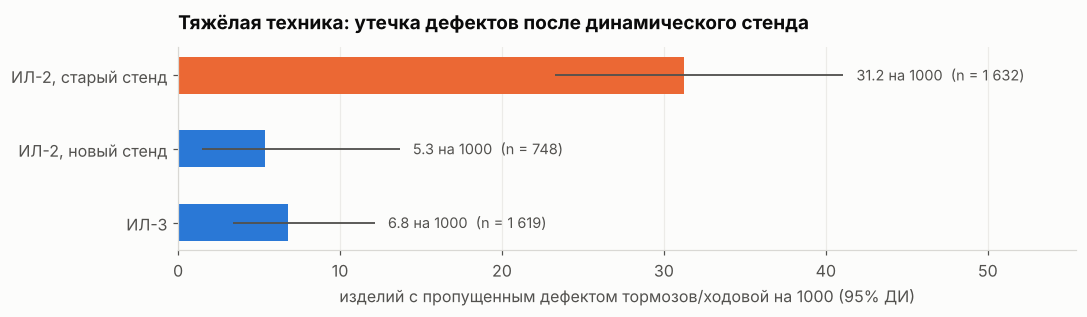

In [6]:
def rate_ci(k, n, alpha=0.05):
    lo = stats.chi2.ppf(alpha / 2, 2 * k) / 2 if k > 0 else 0
    hi = stats.chi2.ppf(1 - alpha / 2, 2 * k + 2) / 2
    return lo / n * 1000, hi / n * 1000

leak[["ci_lo", "ci_hi"]] = [rate_ci(k, n) for k, n in zip(leak["leaked_units"], leak["units"])]
fig, ax = plt.subplots(figsize=(10, 3))
order = ["ИЛ-2, старый стенд", "ИЛ-2, новый стенд", "ИЛ-3"]
L = leak.set_index("dyn_place").loc[order]
yy = np.arange(len(L))[::-1]
ax.barh(yy, L["leak_per_1000"], color=[ORANGE, BLUE, BLUE], height=0.5)
ax.hlines(yy, L["ci_lo"], L["ci_hi"], color=INK_2, lw=1.2)
for y, v, hi, n in zip(yy, L["leak_per_1000"], L["ci_hi"], L["units"]):
    ax.text(hi + 0.8, y, f"{v:.1f} на 1000  (n = {n:,})".replace(",", " "), fontsize=9.5, color=INK_2, va="center")
ax.set_xlim(0, L["ci_hi"].max() * 1.35)
ax.set_yticks(yy, L.index)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color="#ecebe8")
ax.set_xlabel("изделий с пропущенным дефектом тормозов/ходовой на 1000 (95% ДИ)")
ax.set_title("Тяжёлая техника: утечка дефектов после динамического стенда")
save(fig, "04_stand_leak")

old, other = L.loc["ИЛ-2, старый стенд"], L.loc[["ИЛ-2, новый стенд", "ИЛ-3"]].sum()
table = [[old.leaked_units, old.units - old.leaked_units], [other.leaked_units, other.units - other.leaked_units]]
odds, p = stats.fisher_exact(table)
rr = (old.leaked_units / old.units) / (other.leaked_units / other.units)
print(f"Старый стенд vs остальные: утечка в {rr:.1f} раза выше, точный тест Фишера p = {p:.1e}")

Изделия, проверенные на старом стенде ИЛ-2, «пропускали» дефекты тормозов и ходовой в разы чаще, чем проверенные в ИЛ-3 или в ИЛ-2 уже на новом стенде; разница статистически значима.

Оговорка про цензурирование: машины, испытанные на новом стенде, отгружены недавно, и гарантийная часть «утечки» у них ещё не накопилась. Поэтому смотрим и на заводскую часть, которая цензурированию не подвержена, - дефекты, пойманные на обкатке сразу после стенда:

In [7]:
L.assign(run_per_1000=L["caught_on_run"] / L["units"] * 1000)[["units", "caught_on_run", "run_per_1000"]].round(1)

,units,caught_on_run,run_per_1000
dyn_place,,,
"ИЛ-2, старый стенд",1632,23,14.1
"ИЛ-2, новый стенд",748,1,1.3
ИЛ-3,1619,6,3.7


По заводской части картина та же: старый стенд пропускал в разы больше, чем новый и стенд ИЛ-3. Тот же цех, те же модели и бригады - различается только испытательное оборудование. После замены стенда в марте 2026 утечка опустилась до уровня ИЛ-3: проблема решена, но поздно.

Сколько стоила задержка с заменой? Избыточные утечки старого стенда относительно уровня остальных стендов: часть ловилась на обкатке (лишняя доработка), часть ушла к клиенту.

In [8]:
excess_units = old.leaked_units - old.units * other.leaked_units / other.units
warranty_per_leak = L["warranty_cost"].sum() / max(L["warranty_units"].sum(), 1)
share_to_customer = old.warranty_units / old.leaked_units
excess_warranty = excess_units * share_to_customer * warranty_per_leak
print(f"Избыточных утечек на старом стенде: ~{excess_units:.0f} изделий; "
      f"из них до клиента дошло ~{share_to_customer:.0%}")
print(f"Средняя гарантийная выплата по такому случаю: {warranty_per_leak:,.0f} ₽".replace(",", " "))
print(f"Оценка избыточных гарантийных затрат: ~{excess_warranty / 1e6:.2f} млн ₽ за 17 месяцев наблюдения "
      f"(без учёта ещё не проявившихся случаев и репутационного ущерба у дилеров коммерческой техники)")

Избыточных утечек на старом стенде: ~41 изделий; из них до клиента дошло ~57%
Средняя гарантийная выплата по такому случаю: 108 741 ₽
Оценка избыточных гарантийных затрат: ~2.51 млн ₽ за 17 месяцев наблюдения (без учёта ещё не проявившихся случаев и репутационного ущерба у дилеров коммерческой техники)


### Выводы и рекомендации
1. **Мерить гарантию когортами с фиксированным горизонтом** (за 90/180/365 дней с отгрузки) или кривыми дожития. Наивная «доля с заявкой» систематически показывает ложное улучшение на свежих партиях.
2. **Старый тормозной стенд ИЛ-2** пропускал дефекты тормозов и ходовой в разы чаще остальных стендов. Замена в марте 2026 решила проблему - эффект виден в данных.
3. **Процессная рекомендация:** ввести регулярный мониторинг «утечки» по каждому испытательному стенду (дефекты, пойманные на следующих испытаниях или у дилера, в расчёте на 1000 проверенных изделий) - такой показатель за 2-3 месяца сигнализировал бы о проблеме стенда, задолго до накопления гарантийной статистики. Метрика уже есть в хранилище (`fct_units.dyn_lab_id`, `fct_defects.detected_by_test`) и вынесена на дашборд.
4. **Аттестация оборудования:** при закупке/аттестации стендов проверять способность обнаружения на эталонных изделиях с заведомыми дефектами, а не только метрологию.